# Лабораторна робота № 9
## Блендінг зображень за допомогою рівняння Пуассона


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from time import perf_counter
from scipy.sparse import lil_matrix
from scipy.sparse.linalg import spsolve

### 1. Вхідні зображення

Використовую згенеровані зображення м’яча, газону й піску. Значення RGB переведено в діапазон від 0 до 1.

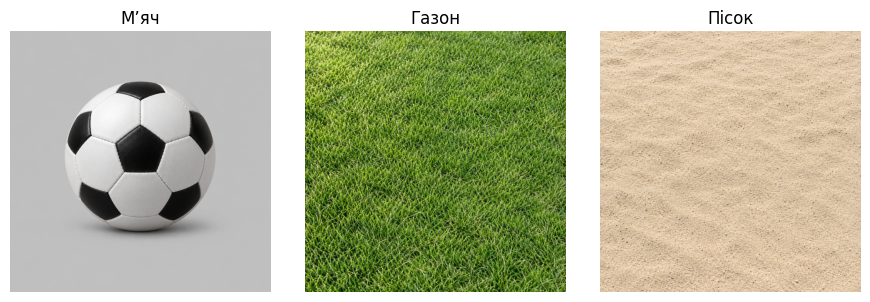

In [2]:
files = ['ball.png', 'grass.png', 'sand.png']
names = ['М’яч', 'Газон', 'Пісок']
images = [Image.open(file).convert('RGB') for file in files]


def resize(image, size):
    return np.array(image.resize(size), dtype=float) / 255


def show(images, titles):
    fig, axes = plt.subplots(1, len(images), figsize=(3 * len(images), 3))
    for ax, image, title in zip(axes, images, titles):
        ax.imshow(np.clip(image, 0, 1))
        ax.set_title(title)
        ax.axis('off')
    plt.tight_layout()
    plt.show()


show([np.array(image) / 255 for image in images], names)

### 2. Рівняння Пуассона

Внутрішні пікселі знаходжу за градієнтами джерела та відомими значеннями на границі:

$$4u_{i,j}-u_{i-1,j}-u_{i+1,j}-u_{i,j-1}-u_{i,j+1}=b_{i,j}.$$

In [3]:
def right_side(source):
    gx = source[:, 1:] - source[:, :-1]
    gy = source[1:] - source[:-1]
    b = np.zeros_like(source)
    b[:, :-1] -= gx
    b[:, 1:] += gx
    b[:-1] -= gy
    b[1:] += gy
    return b

### 3. Метод Зейделя

Послідовно оновлюю пікселі до максимальної зміни за ітерацію меншої за `1e-9`. Границя залишається сталою.

In [4]:
def seidel(source, border, eps=1e-9, max_iter=20000):
    b = right_side(source)
    u = border.copy()
    u[1:-1, 1:-1] = 0
    h, w = u.shape[:2]

    for step in range(1, max_iter + 1):
        old = u.copy()
        for i in range(1, h - 1):
            for j in range(1, w - 1):
                u[i, j] = (u[i - 1, j] + u[i + 1, j]
                           + u[i, j - 1] + u[i, j + 1] + b[i, j]) / 4
        if np.max(np.abs(u - old)) < eps:
            return u, step

    raise RuntimeError('Недостатньо ітерацій для заданої точності')

### 4. SciPy

Формую розріджену систему рівнянь і розв’язую її функцією `spsolve`.

In [5]:
def scipy_solve(source, border):
    h, w = source.shape[0] - 2, source.shape[1] - 2
    b = right_side(source)[1:-1, 1:-1].copy()
    b[0] += border[0, 1:-1]
    b[-1] += border[-1, 1:-1]
    b[:, 0] += border[1:-1, 0]
    b[:, -1] += border[1:-1, -1]
    A = lil_matrix((h * w, h * w))

    for i in range(h):
        for j in range(w):
            k = i * w + j
            A[k, k] = 4
            if i > 0:
                A[k, k - w] = -1
            if i < h - 1:
                A[k, k + w] = -1
            if j > 0:
                A[k, k - 1] = -1
            if j < w - 1:
                A[k, k + 1] = -1

    u = border.copy()
    u[1:-1, 1:-1] = spsolve(A.tocsr(), b.reshape(h * w, 3)).reshape(h, w, 3)
    return u

### 5. Відновлення зображень

Порівнюю обидва методи на трьох зображеннях для областей 16 × 16, 32 × 32 і 48 × 48. Вимірюю час обчислень, включно з побудовою системи для SciPy, без читання файлів і показу зображень.

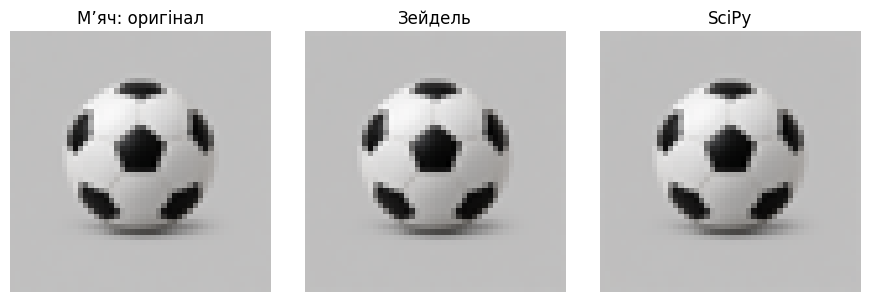

М’яч — середня похибка відновлення: 1e-07


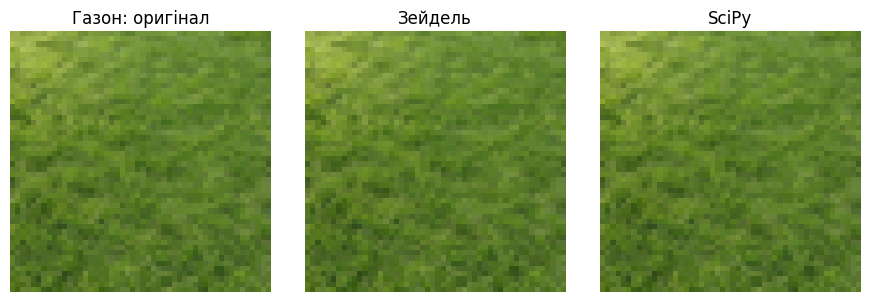

Газон — середня похибка відновлення: 1e-07


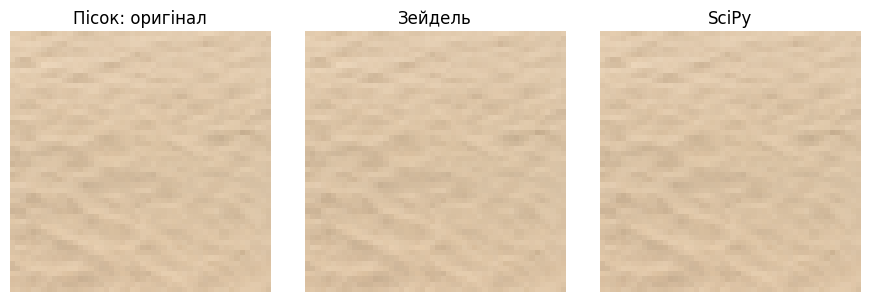

Пісок — середня похибка відновлення: 1e-07


In [6]:
sizes = [16, 32, 48]
rows = []

for name, image in zip(names, images):
    for size in sizes:
        source = resize(image, (size + 2, size + 2))
        border = source.copy()
        border[1:-1, 1:-1] = 0

        start = perf_counter()
        result1, steps = seidel(source, border)
        time1 = perf_counter() - start

        start = perf_counter()
        result2 = scipy_solve(source, border)
        time2 = perf_counter() - start

        error = np.max(np.abs(result1 - result2))
        rows.append(['Відновлення', name, size, time1, time2, steps, error])
        if size == sizes[-1]:
            show([source, result1, result2], [name + ': оригінал', 'Зейдель', 'SciPy'])
            print(name, '— середня похибка відновлення:',
                  round(np.mean(np.abs(result1 - source)), 7))

### 6. Безшовне вставлення

Вставляю м’яч на газон і пісок. Градієнти беру з джерела, граничні значення — з фону.

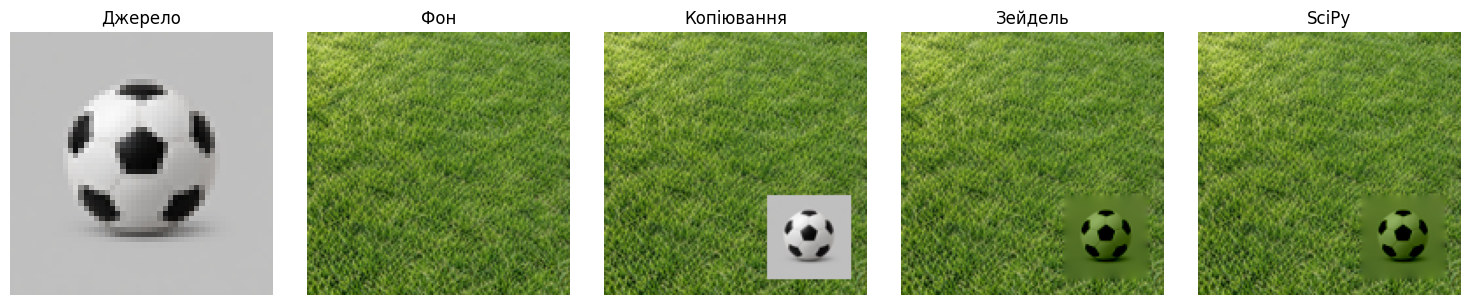

М’яч → газон


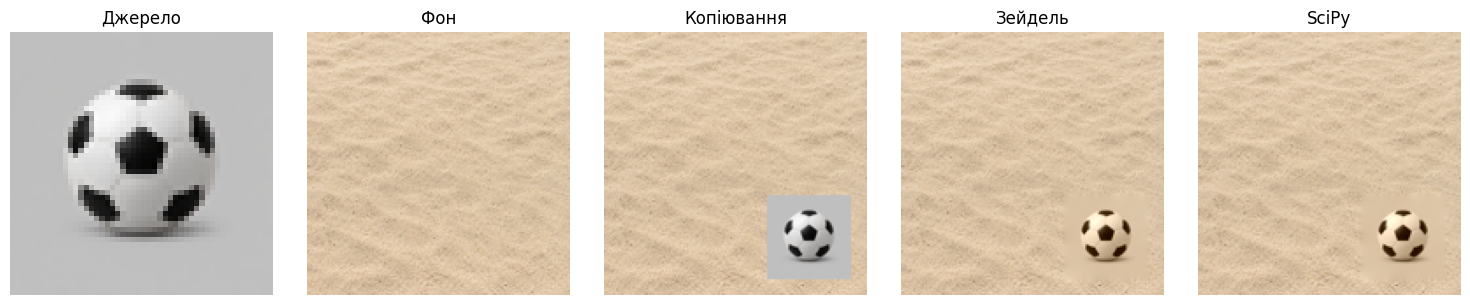

М’яч → пісок


In [7]:
pairs = [(0, 1), (0, 2)]

for src, dst in pairs:
    name = names[src] + ' → ' + names[dst].lower()
    for size in sizes:
        source = resize(images[src], (size + 2, size + 2))
        background = resize(images[dst], (150, 150))
        y, x = 150 - size - 10, 150 - size - 10
        border = background[y:y + size + 2, x:x + size + 2].copy()

        start = perf_counter()
        patch1, steps = seidel(source, border)
        time1 = perf_counter() - start

        start = perf_counter()
        patch2 = scipy_solve(source, border)
        time2 = perf_counter() - start

        error = np.max(np.abs(patch1 - patch2))
        rows.append(['Вставлення', name, size, time1, time2, steps, error])
        if size == sizes[-1]:
            plain = background.copy()
            result1 = background.copy()
            result2 = background.copy()
            area = np.s_[y + 1:y + size + 1, x + 1:x + size + 1]
            plain[area] = source[1:-1, 1:-1]
            result1[area] = patch1[1:-1, 1:-1]
            result2[area] = patch2[1:-1, 1:-1]
            show([source, background, plain, result1, result2],
                 ['Джерело', 'Фон', 'Копіювання', 'Зейдель', 'SciPy'])
            print(name)

### 7. Порівняння методів


In [8]:
table = pd.DataFrame(rows, columns=[
    'Задача', 'Зображення', 'Розмір', 'Зейдель, с', 'SciPy, с',
    'Ітерації', 'Різниця методів'])
print(table.to_string(index=False, float_format=lambda x: f'{x:.6f}'))

     Задача   Зображення  Розмір  Зейдель, с  SciPy, с  Ітерації  Різниця методів
Відновлення         М’яч      16    1.454724  0.004832       508         0.000000
Відновлення         М’яч      32   20.477931  0.019832      1772         0.000000
Відновлення         М’яч      48   98.218955  0.040931      3716         0.000000
Відновлення        Газон      16    1.531737  0.005128       500         0.000000
Відновлення        Газон      32   19.776973  0.018687      1741         0.000000
Відновлення        Газон      48   92.834101  0.042256      3647         0.000000
Відновлення        Пісок      16    1.469347  0.005179       516         0.000000
Відновлення        Пісок      32   20.532328  0.018516      1803         0.000000
Відновлення        Пісок      48   97.350286  0.041825      3784         0.000000
 Вставлення М’яч → газон      16    1.427178  0.004576       489         0.000000
 Вставлення М’яч → газон      32   19.299864  0.018568      1701         0.000000
 Вставлення М’яч

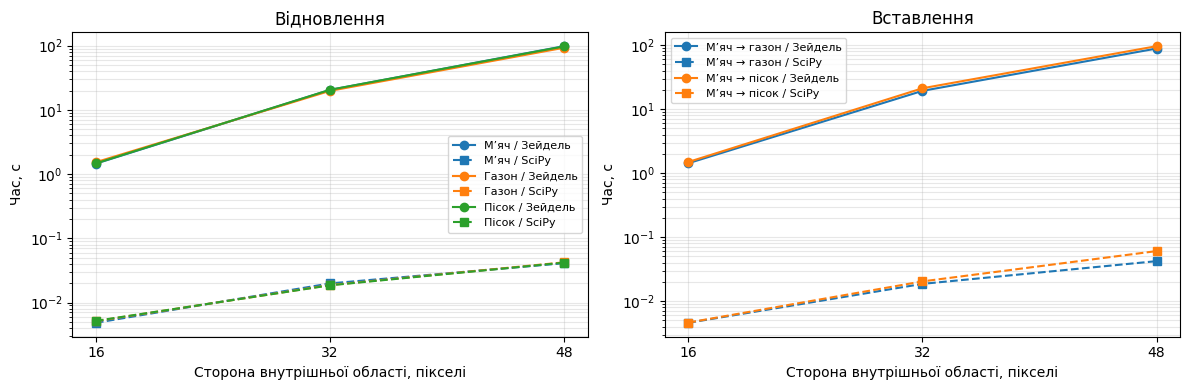

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
colors = ['tab:blue', 'tab:orange', 'tab:green']

for ax, task in zip(axes, ['Відновлення', 'Вставлення']):
    part = table[table['Задача'] == task]
    for color, name in zip(colors, part['Зображення'].unique()):
        data = part[part['Зображення'] == name]
        ax.plot(data['Розмір'], data['Зейдель, с'], 'o-', color=color,
                label=name + ' / Зейдель')
        ax.plot(data['Розмір'], data['SciPy, с'], 's--', color=color,
                label=name + ' / SciPy')
    ax.set_yscale('log')
    ax.set_title(task)
    ax.set_xlabel('Сторона внутрішньої області, пікселі')
    ax.set_ylabel('Час, с')
    ax.set_xticks(sizes)
    ax.grid(True, which='both', alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

### Висновок

Обидва методи дають близькі результати; SciPy у цих вимірюваннях швидший.

In [12]:
for task in ['Відновлення', 'Вставлення']:
    data = table[table['Задача'] == task]
    speed = data['Зейдель, с'] / data['SciPy, с']
    print(f'{task}: SciPy швидший у {speed.min():.1f}  –  {speed.max():.1f} раза.')
print('Найбільша різниця методів:', round(table['Різниця методів'].max(), 7))

Відновлення: SciPy швидший у 283.7  –  2399.6 раза.
Вставлення: SciPy швидший у 311.9  –  2104.4 раза.
Найбільша різниця методів: 2e-07
